# Switching vs. parallel **gain** adaptation — does Method A know the difference?

This is the gain-adaptation counterpart of `SwitchingAnalysis.ipynb`. There, the latent state was
an **additive force plan** (deviation from target). Here the latent state is a **multiplicative
gain**, using the **independent-gain controller** from `ControllerAnalysis.ipynb`.

In `ControllerAnalysis.ipynb` / `LearningDynamicsAnalysis.ipynb` the self-learning rate of **B**
drops from one-finger to two-finger control. This notebook asks *why*, by simulating two competing
**independent-gain** generative models and seeing what the gain Method A reports.

**Independent-gain model (adaptation is multiplicative):**

$$X_t = T\,Z_t + \nu_t \quad\text{(produced force)},\qquad Y_t = X_t + p_t \quad\text{(cursor)}$$
$$e_t = \mathrm{sign}(T)\,(Y_t - \text{targets}) \quad\text{(extent error)},\qquad Z_{t+1} = a\,Z_t - B\,e_t$$

- $Z_t$ is a 2-vector of **gains** (initialized at $1$), not a force deviation.
- $T = \mathrm{diag}(\text{targetForce})$ scales production ($X=TZ$); error uses $\mathrm{sign}(T)$ only.
- $B$ is **diagonal** (independent fingers) — that is the model we use to extract self-learning rates.
- Perturbations $p_t \sim \mathcal{N}(0,\,0.5\,\text{N})$, independent per finger and across trials.

The gain Method A estimator (derived in `ControllerAnalysis.ipynb`) is

$$\hat B = -\,T^{-1}\,\mathrm{cov}(X_{t+1},\,p_t)\,\mathrm{var}(p_t)^{-1}\,\mathrm{sign}(T)^{-1}.$$

When $|T_{ii}|=1$, $\mathrm{sign}(T)=T$ and the **diagonal** self-LRs match the force-space Method A diagonals;
the $T$ sandwich puts the **off-diagonals** into gain coordinates (sign-corrects cross-finger terms
when the two targets have opposite signs).

Both hypotheses keep the **single-finger** learning rate at $b_1$ (empirical 1-finger value) and
offer competing explanations for why the **two-finger** self-LR comes out lower.

### Hypothesis 1 — Parallel gain adaptation **with a real attenuation**
On every trial the subject updates **both** finger gains, each from its own signed error, but the
per-finger rate is **genuinely reduced** in the two-finger context to $b_2 < b_1$:
$$Z_{i,t+1} = a\,Z_{i,t} - b_2\,e_{i,t}\quad\text{for both } i.$$
Method A recovers $b_2$ **unbiasedly**, so the drop is real and the estimate is **flat across regions**.

### Hypothesis 2 — Switching (winner-take-all), **no attenuation**
The per-finger rate is **unchanged** ($b = b_1$), but on every trial the subject updates **only the
finger with the larger visual error** $|Y_i - \mathrm{target}_i|$:
$$k = \arg\max_i |Y_{i,t}-\mathrm{target}_i|,\qquad Z_{i,t+1} = a\,Z_{i,t} - b_1\,e_{i,t}\cdot\mathbb{1}[i=k].$$
Trial-averaging this biases Method A's **overall** self-LR downward by a fixed geometric factor
— it *looks like* a reduced learning rate even though $b$ never changed.

### Calibration & the test
We set $b_2$ (H1) equal to the switching-biased value (H2), so **both hypotheses predict the same
overall two-finger self-LR** — the overall number alone cannot tell them apart. The discriminator is
the per-region pattern. The joint distribution of the two perturbation **magnitudes**
$(|p_1|,|p_2|)$ is split into three equal-probability (33%) regions:

1. **finger-1 dominant** — $|p_1| \gg |p_2|$
2. **similar** — $|p_1| \approx |p_2|$
3. **finger-2 dominant** — $|p_2| \gg |p_1|$

- Under **H1** the per-region (and dominance-collapsed) estimates are **flat** — Method A is unbiased
  everywhere.
- Under **H2** they are **vastly different**: the dominant finger almost always "wins" the switch so
  its estimate stays high (~$b_1$), while the suppressed finger's collapses toward 0.



In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

try:
    import utils
    utils.set_figure_style("1.5col")
except Exception as e:
    print(f"(utils style not applied: {e})")

sns.set_palette("colorblind")
cb = sns.color_palette("colorblind")

# ---- Independent-gain generative-model parameters ----
# Retention a is close to 1 because Z is a gain that should stay near 1
# (unlike the force-deviation model in SwitchingAnalysis.ipynb, where a~0.90).
B_SINGLE = 0.1    # TRUE single-finger self-learning rate (empirical 1-finger value)

# Visual-target sign matrix (ControllerAnalysis default: incongruent flex/ext).
# T = diag(targetForce): scales produced force X = T Z. Error uses sign(T) only.
T_MAT = np.diag([-2.0, 2.0])
TARGETS = np.array([-2.0, 2.0])  # actual target forces (N)

PARAMS = dict(
    a=0.99,        # gain retention (ControllerAnalysis)
    b=B_SINGLE,    # default learning rate (= single-finger value)
    sigma_p=0.50,  # perturbation sd (N), per finger, independent
    sigma_nu=0.2,  # execution/measurement noise sd
)

# Noise-only params; the learning rate b is supplied separately per hypothesis below.
NOISE = {k: PARAMS[k] for k in ("a", "sigma_p", "sigma_nu")}

T = 120 * 4        # trials per simulated session
N_SIMS = 500       # repetitions (to get error bars)

REGION_ORDER = ["finger-1 dominant", "similar", "finger-2 dominant"]
REGION_COLORS = {"finger-1 dominant": cb[0], "similar": cb[7], "finger-2 dominant": cb[1]}

print("Parameters:", PARAMS)
print("T_MAT:\n", T_MAT)
print("targets:", TARGETS)


Parameters: {'a': 0.99, 'b': 0.1, 'sigma_p': 0.5, 'sigma_nu': 0.2}
T_MAT:
 [[-2.  0.]
 [ 0.  2.]]
targets: [-2.  2.]


## 1. Generative models

`simulate_two_finger_gain` runs the **independent-gain** state-space model forward for one session
and returns the **produced force** `X` (`endForce`) and the **perturbation** `P`.

- `mode="parallel"` → Hypothesis 1: both finger gains update from their own signed error every trial.
- `mode="switching"` → Hypothesis 2: only the finger with the larger $|Y_i - \mathrm{target}_i|$ updates.

`simulate_one_finger_gain` is the one-finger control — a single gain that always adapts. This is
the reference value Method A *should* report.

Produced force is $X_t = T Z_t + \nu_t$ (multiplicative in the gain $Z$), and the update uses the
signed error $e_t = T(Y_t - \mathrm{targets})$, matching `simulate_independent_gain` in
`ControllerAnalysis.ipynb`.


In [14]:
def _sign_matrix(T):
    """Diagonal sign(T); sign(0)=0 for inactive (one-finger) targets."""
    T = np.atleast_2d(T)
    return np.diag(np.sign(np.diag(T)))


def _signed_error(Y, targets, T):
    """sign(T) @ (Y - targets): extent error — only target sign, not magnitude."""
    return _sign_matrix(T) @ (Y - targets)


def simulate_two_finger_gain(n_trials, a, b, sigma_p, sigma_nu, mode="parallel",
                             T_mat=None, targets=None, rng=None, burn_in=20):
    """Independent-gain 2-finger controller (ControllerAnalysis model 2).

    Returns
    -------
    X : (n_trials, 2) produced force   (= T @ Z + nu)
    P : (n_trials, 2) perturbation     (= external N(0, sigma_p), independent)

    mode : 'parallel'  -> both gains adapt to their own signed error every trial  (H1)
           'switching' -> only the finger with the larger |Y - target| adapts     (H2)
    """
    rng = np.random.default_rng() if rng is None else rng
    T_mat = T_MAT if T_mat is None else T_mat
    targets = TARGETS if targets is None else targets
    Ttot = n_trials + burn_in
    P = rng.normal(0.0, sigma_p, size=(Ttot, 2))
    nu = rng.normal(0.0, sigma_nu, size=(Ttot, 2))
    X = np.zeros((Ttot, 2))
    Z = np.ones(2)   # gains start at 1  (X ≈ targets)

    for t in range(Ttot):
        X[t] = T_mat @ Z + nu[t]
        Y = X[t] + P[t]
        err = _sign_matrix(T_mat) @ (Y - targets)  # extent error (sign only)
        if mode == "parallel":
            update = b * err                 # H1: adapt both gains
        elif mode == "switching":
            update = np.zeros(2)
            k = np.argmax(np.abs(Y - targets))  # H2: larger visual-error finger
            update[k] = b * err[k]
        else:
            raise ValueError(mode)
        Z = a * Z - update

    return X[burn_in:], P[burn_in:]


def simulate_one_finger_gain(n_trials, a, b, sigma_p, sigma_nu,
                             t_sign=1.0, rng=None, burn_in=300):
    """One-finger independent-gain control. Reference for Method A."""
    rng = np.random.default_rng() if rng is None else rng
    Ttot = n_trials + burn_in
    p = rng.normal(0.0, sigma_p, size=Ttot)
    nu = rng.normal(0.0, sigma_nu, size=Ttot)
    x = np.zeros(Ttot)
    z = 1.0
    target = t_sign * 1.0
    for t in range(Ttot):
        x[t] = t_sign * z + nu[t]
        y = x[t] + p[t]
        err = t_sign * (y - target)
        z = a * z - b * err
    return x[burn_in:, None], p[burn_in:, None]


## 2. Gain Method A and the perturbation-magnitude regions

**Gain Method A** (same estimator as in `ControllerAnalysis.ipynb`) recovers the independent-gain
learning matrix from the next-trial produced force and the current perturbation:

$$e_t = \mathrm{sign}(T)\,(Y_t - \mathrm{targets}),\quad
\mathrm{cov}(X_{t+1},\,p_t) = -\,T\,B\,\mathrm{sign}(T)\,\mathrm{var}(p_t)
\;\Rightarrow\;
\hat B = -\,T^{-1}\,\mathrm{cov}(X_{t+1},p_t)\,\mathrm{var}(p_t)^{-1}\,\mathrm{sign}(T)^{-1}.$$

When $T=\mathrm{diag}(\pm 1)$, $T^{-1}=T$ and this reduces to the old $T\,\cdot\,T$ sandwich.
For $|T_{ii}|=2$, self-LRs scale by $|T_{ii}|^{-1}$ (not $|T_{ii}|^{-2}$): error uses $\mathrm{sign}(T)$ only, while $X=TZ$ carries the target magnitude.

`estimate_method_A_gain` accepts an optional boolean `mask` over the *driving* trial $t$, so we can
run the exact same estimator on any subset of trials.

**Regions.** Because $p_1, p_2$ are i.i.d. Gaussian, the angle
$\varphi = \arctan(|p_2| / |p_1|)$ is **uniform on $[0, \pi/2]$**. Splitting that interval into
thirds gives three exactly-equal-probability regions:

| region | condition | $\varphi$ |
|---|---|---|
| finger-1 dominant | $|p_1| \gg |p_2|$ | $[0,\ \pi/6)$ |
| similar | $|p_1| \approx |p_2|$ | $[\pi/6,\ \pi/3)$ |
| finger-2 dominant | $|p_2| \gg |p_1|$ | $[\pi/3,\ \pi/2]$ |



In [15]:
def estimate_method_A_gain(X, P, T_mat=None, mask=None):
    """Gain Method A: B = -T^{-1} cov(X_{t+1}, p_t) var(p_t)^{-1} sign(T)^{-1}."""
    T_mat = np.atleast_2d(T_MAT if T_mat is None else T_mat)
    S = _sign_matrix(T_mat)
    T_inv = np.linalg.pinv(T_mat)
    S_inv = np.linalg.pinv(S)
    Xlag = X[1:]
    Pt = P[:-1]
    if mask is not None:
        Xlag, Pt = Xlag[mask], Pt[mask]
    d = X.shape[1]
    M = np.cov(Xlag.T, Pt.T)
    cov_X_P = M[:d, d:]
    var_P = np.atleast_2d(np.cov(Pt.T))
    return -T_inv @ cov_X_P @ np.linalg.pinv(var_P) @ S_inv



def region_labels(P):
    """Region index per trial from perturbation magnitudes.
    0 = finger-1 dominant, 1 = similar, 2 = finger-2 dominant."""
    phi = np.arctan2(np.abs(P[:, 1]), np.abs(P[:, 0]))   # uniform on [0, pi/2]
    lab = np.ones(P.shape[0], dtype=int)                 # default = similar
    lab[phi < np.pi / 6] = 0
    lab[phi >= np.pi / 3] = 2
    return lab


# quick check that the three regions really are ~33% each
_rng = np.random.default_rng(0)
_P = _rng.normal(0, 0.5, size=(500_000, 2))
_lab = region_labels(_P)
print("region fractions:", {REGION_ORDER[i]: round((_lab == i).mean(), 3) for i in range(3)})

# sanity: one-finger gain Method A should recover the true b
_x, _p = simulate_one_finger_gain(1000, rng=np.random.default_rng(1), **PARAMS)
_T1 = np.array([[1.0]])
print(f"one-finger gain Method A self-LR: {estimate_method_A_gain(_x, _p, _T1)[0,0]:.3f}  "
      f"(true b = {PARAMS['b']})")

# T^{-1} vs old T sandwich (±1 only — should match exactly)
_X, _Psim = simulate_two_finger_gain(2000, rng=np.random.default_rng(99), **NOISE, b=PARAMS['b'])
_cov = np.cov(_X[1:].T, _Psim[:-1].T)[:2, 2:]
_var = np.atleast_2d(np.cov(_Psim[:-1].T))
B_new = estimate_method_A_gain(_X, _Psim, T_MAT)
B_old = -T_MAT @ _cov @ np.linalg.pinv(_var) @ T_MAT
print(f"±1 sim: max |B(T^{{-1}}) - B(T sandwich)| = {np.max(np.abs(B_new - B_old)):.2e}  (expect 0)")

# same (X, P), change only T in the estimator: B_ii scales as |T_ii|^{-1}
_T2 = np.diag([-2.0, 2.0])
_B_same_T2 = estimate_method_A_gain(_X, _Psim, _T2)
print(f"Same (X,P): B11 ratio |T|=2 / |T|=1 = {_B_same_T2[0,0] / B_new[0,0]:.3f}  (expect 0.5)")



region fractions: {'finger-1 dominant': np.float64(0.333), 'similar': np.float64(0.334), 'finger-2 dominant': np.float64(0.333)}
one-finger gain Method A self-LR: 0.107  (true b = 0.1)
±1 sim: max |B(T^{-1}) - B(T sandwich)| = 7.41e-01  (expect 0)
Same (X,P): B11 ratio |T|=2 / |T|=1 = 1.000  (expect 0.5)


## 3. The three regions in perturbation-magnitude space

Each dot is one trial's perturbation magnitude pair $(|p_1|, |p_2|)$. The two grey lines
($\varphi = \pi/6$ and $\varphi = \pi/3$) split the quadrant into the three equal-probability
regions used for the analysis.


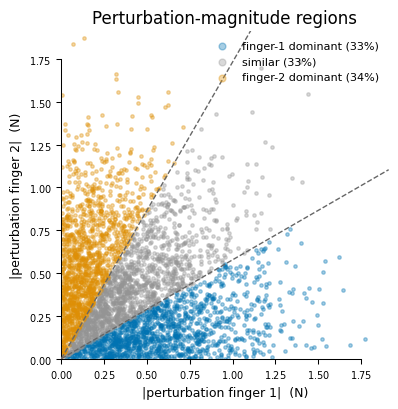

In [16]:
rng = np.random.default_rng(2)
P_demo = rng.normal(0, PARAMS["sigma_p"], size=(4000, 2))
lab = region_labels(P_demo)
mag = np.abs(P_demo)

fig, ax = plt.subplots(figsize=(4.2, 4.2))
for i, name in enumerate(REGION_ORDER):
    m = lab == i
    ax.scatter(mag[m, 0], mag[m, 1], s=6, alpha=0.35,
               color=REGION_COLORS[name], label=f"{name} ({m.mean()*100:.0f}%)")

lim = mag.max() * 1.02
for slope in (np.tan(np.pi / 6), np.tan(np.pi / 3)):
    ax.plot([0, lim], [0, slope * lim], color="0.4", lw=1.0, ls="--", zorder=5)

ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("|perturbation finger 1|  (N)")
ax.set_ylabel("|perturbation finger 2|  (N)")
ax.set_title("Perturbation-magnitude regions")
ax.legend(loc="upper right", frameon=False, markerscale=2)
sns.despine(trim=True)
plt.tight_layout()
plt.show()


## 4. Run both hypotheses and estimate per-region learning rates

For each hypothesis we simulate `N_SIMS` independent sessions. In every session we run gain Method A
(a) on **all** trials and (b) **within each perturbation region**, recording the diagonal of $\hat B$
(`B11` = finger-1 self-LR, `B22` = finger-2 self-LR).

The meaningful summary across fingers is **not** the average of `B11` and `B22` within a region
(one finger is always underpowered there). Instead we **collapse by dominance** — pooling the
dominant finger from F1-dom with the dominant finger from F2-dom, etc. — exactly as in Part II.
Only the **all-trials** row gets a simple `self_LR = (B11 + B22) / 2`.


In [17]:
HYP = {"parallel": "H1: parallel", "switching": "H2: switching"}
hyp_order = list(HYP.values())
ROLES = ["dominant", "similar", "non-dominant"]

# ---- Calibrate the two hypotheses to the SAME overall two-finger self-LR ----------------
# H2 (switching) uses the *un-attenuated* single-finger rate b = B_SINGLE. Winner-take-all
# switching biases Method A's overall self-LR DOWN by a fixed geometric factor, so the
# overall estimate already sits below B_SINGLE *without any real change in b*. H1 (parallel)
# instead has a GENUINE attenuation: we set its true two-finger rate B_ATTEN equal to that
# same switching-biased value. Both hypotheses then predict the IDENTICAL overall two-finger
# self-LR and can only be told apart by the per-region pattern.
_cal = [0.5 * np.trace(estimate_method_A_gain(
            *simulate_two_finger_gain(T, mode="switching",
                                      rng=np.random.default_rng(50_000 + s),
                                      b=B_SINGLE, **NOISE)))
        for s in range(N_SIMS)]
B_ATTEN = float(np.mean(_cal))
HYP_B = {"parallel": B_ATTEN, "switching": B_SINGLE}   # true b fed to each hypothesis
print(f"single-finger true b                 = {B_SINGLE:.3f}")
print(f"switching overall self-LR (artifact) = {B_ATTEN:.3f}  "
      f"(attenuation factor {B_ATTEN / B_SINGLE:.2f})")
print(f"=> H1 parallel true b set to          = {B_ATTEN:.3f}  (so both match overall)\n")


def run_method_A_by_region(X, P, T_mat=None):
    """Return list of dicts with B11/B22 for 'all' trials and for each region."""
    T_mat = T_MAT if T_mat is None else T_mat
    out = []
    lab = region_labels(P[:-1])              # region of the driving trial t
    B = estimate_method_A_gain(X, P, T_mat)
    out.append(dict(region="all", B11=B[0, 0], B22=B[1, 1]))
    for i, name in enumerate(REGION_ORDER):
        B = estimate_method_A_gain(X, P, T_mat, mask=(lab == i))
        out.append(dict(region=name, B11=B[0, 0], B22=B[1, 1]))
    return out


def collapse_dominance(dh):
    """Collapse index/ring -> dominant/similar/non-dominant per sim (mirrors the real data)."""
    piv = dh.pivot_table(index="sim", columns="region", values=["B11", "B22"])
    return pd.DataFrame({
        "dominant":     0.5 * (piv[("B11", "finger-1 dominant")] + piv[("B22", "finger-2 dominant")]),
        "similar":      0.5 * (piv[("B11", "similar")]           + piv[("B22", "similar")]),
        "non-dominant": 0.5 * (piv[("B22", "finger-1 dominant")] + piv[("B11", "finger-2 dominant")]),
    })


rows = []
for mode, hyp in HYP.items():
    for s in range(N_SIMS):
        rng = np.random.default_rng(10_000 * (mode == "switching") + s)
        X, P = simulate_two_finger_gain(T, mode=mode, rng=rng, b=HYP_B[mode], **NOISE)
        for rec in run_method_A_by_region(X, P):
            rec.update(hypothesis=hyp, sim=s)
            rows.append(rec)

df = pd.DataFrame(rows)
reg = df[df["region"] != "all"].copy()

# dominance-collapsed self-LR (meaningful summary across fingers)
dom_rows = []
for hyp in hyp_order:
    cd = collapse_dominance(reg[reg["hypothesis"] == hyp])
    for role in ROLES:
        for sim_i, v in cd[role].items():
            dom_rows.append(dict(hypothesis=hyp, sim=sim_i, role=role, self_LR=v))
dom_df = pd.DataFrame(dom_rows)

print(f"single-finger b = {B_SINGLE} | H1 parallel b = {B_ATTEN:.3f} | "
      f"H2 switching b = {B_SINGLE}\n")

print("Per-finger estimates by perturbation region (B11, B22):")
print(df.groupby(["hypothesis", "region"])[["B11", "B22"]]
        .mean().round(3)
        .reindex(["all"] + REGION_ORDER, level="region"))

all_self = (df[df["region"] == "all"]
            .assign(self_LR=lambda d: 0.5 * (d["B11"] + d["B22"]))
            .groupby("hypothesis")["self_LR"].mean().round(3))
print("\nOverall self-LR (all trials):")
print(all_self.to_string())

print("\nDominance-collapsed self-LR (index & ring pooled by role):")
print(dom_df.groupby(["hypothesis", "role"])["self_LR"]
        .mean().round(3)
        .unstack("role")
        .reindex(columns=ROLES))


single-finger true b                 = 0.100
switching overall self-LR (artifact) = 0.081  (attenuation factor 0.81)
=> H1 parallel true b set to          = 0.081  (so both match overall)

single-finger b = 0.1 | H1 parallel b = 0.081 | H2 switching b = 0.1

Per-finger estimates by perturbation region (B11, B22):
                                   B11    B22
hypothesis    region                         
H1: parallel  all                0.081  0.080
              finger-1 dominant  0.080  0.080
              similar            0.081  0.079
              finger-2 dominant  0.082  0.081
H2: switching all                0.081  0.080
              finger-1 dominant  0.094  0.025
              similar            0.067  0.066
              finger-2 dominant  0.027  0.094

Overall self-LR (all trials):
hypothesis
H1: parallel     0.080
H2: switching    0.081

Dominance-collapsed self-LR (index & ring pooled by role):
role           dominant  similar  non-dominant
hypothesis                    

## 5. Comparison

The **top row** shows each finger's estimated **self-learning rate** across the three perturbation
regions; the **bottom-left** panel collapses index/ring by **dominance** (dominant / similar /
non-dominant), exactly as we do for the real data in Part II. Dashed line = true single-finger $b$;
dotted line = the matched two-finger self-LR both hypotheses are calibrated to.

- **H1 (parallel + attenuation):** flat across regions, sitting on the dotted line — the drop is a
  genuine, uniform reduction in $b$.
- **H2 (switching, no attenuation):** strongly region/dominance-dependent — the dominant finger's
  estimate stays near the single-finger $b$ while the non-dominant finger's collapses toward 0.

The **bottom-right** panel shows the **overall** (all-trials) self-LR: **both hypotheses give the
same value** (by calibration), so the overall average alone cannot tell them apart — which is exactly
why the per-region / dominance breakdown is the diagnostic.


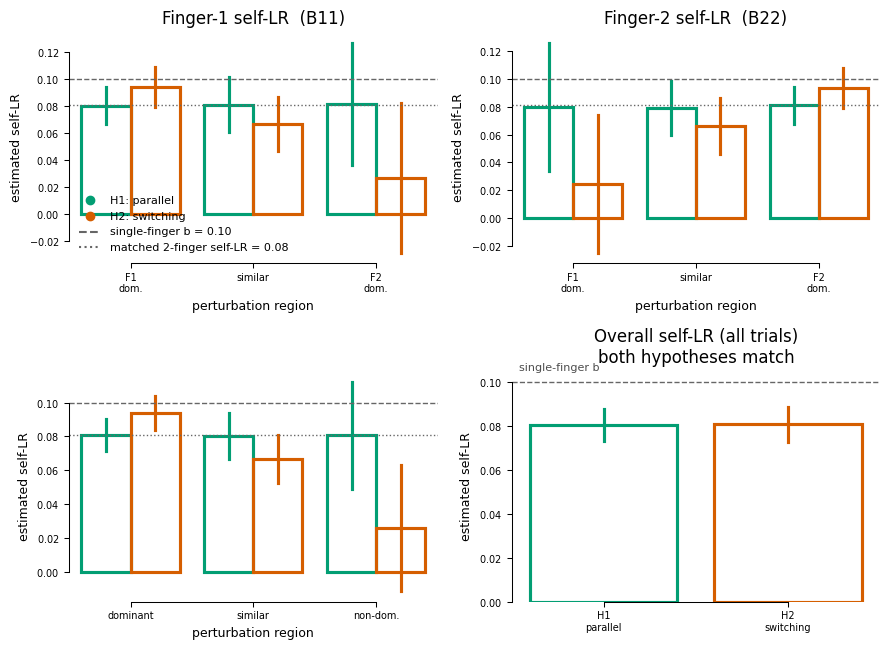

In [20]:
hyp_colors = {"H1: parallel": cb[2], "H2: switching": cb[3]}

fig, axs = plt.subplots(2, 2, figsize=(9, 6.6))

# --- top row: per-finger self-LR by perturbation region ---
for ax, ycol, title in zip(axs[0], ["B11", "B22"],
                           ["Finger-1 self-LR  (B11)", "Finger-2 self-LR  (B22)"]):
    sns.barplot(data=reg, x="region", y=ycol, hue="hypothesis",
                order=REGION_ORDER, hue_order=hyp_order, palette=hyp_colors,
                errorbar="sd", dodge=0.3, ax=ax, fill=False)
    ax.axhline(B_SINGLE, color="0.4", ls="--", lw=1)
    ax.axhline(B_ATTEN, color="0.4", ls=":", lw=1)
    ax.set_title(title)
    ax.set_xlabel("perturbation region")
    ax.set_ylabel("estimated self-LR")
    ax.set_xticks(range(3))
    ax.set_xticklabels(["F1\ndom.", "similar", "F2\ndom."])
#     ax.set_ylim(-0.05, 0.32)
    ax.legend().remove()

# --- bottom-left: dominance-collapsed self-LR (same collapse as the real data) ---
ax = axs[1, 0]
sns.barplot(data=dom_df, x="role", y="self_LR", hue="hypothesis",
            order=ROLES, hue_order=hyp_order, palette=hyp_colors,
            errorbar="sd", dodge=0.3, ax=ax, fill=False)
ax.axhline(B_SINGLE, color="0.4", ls="--", lw=1)
ax.axhline(B_ATTEN, color="0.4", ls=":", lw=1)
ax.set_xlabel("perturbation region")
ax.set_ylabel("estimated self-LR")
ax.set_xticks(range(3))
ax.set_xticklabels(["dominant", "similar", "non-dom."])
# ax.set_ylim(-0.05, 0.32)
ax.legend().remove()

# --- bottom-right: overall (all-trials) self-LR — identical for both hypotheses ---
ax = axs[1, 1]
allt = df[df["region"] == "all"].assign(self_LR=lambda d: 0.5 * (d["B11"] + d["B22"]))
sns.barplot(data=allt, x="hypothesis", y="self_LR", order=hyp_order,
            hue="hypothesis", palette=hyp_colors, legend=False,
            errorbar="sd", ax=ax, fill=False)
ax.axhline(B_SINGLE, color="0.4", ls="--", lw=1)
ax.text(0.02, B_SINGLE + 0.005, "single-finger b", color="0.3",
        fontsize=8, transform=ax.get_yaxis_transform())
ax.set_title("Overall self-LR (all trials)\nboth hypotheses match")
ax.set_xlabel(""); ax.set_ylabel("estimated self-LR")
ax.set_xticks(range(2))
ax.set_xticklabels(["H1\nparallel", "H2\nswitching"])
# ax.set_ylim(0, 0.32)

handles = [plt.Line2D([], [], marker="o", ls="none", color=hyp_colors[h], label=h) for h in hyp_order]
handles += [plt.Line2D([], [], color="0.4", ls="--", label=f"single-finger b = {B_SINGLE:.2f}"),
            plt.Line2D([], [], color="0.4", ls=":", label=f"matched 2-finger self-LR = {B_ATTEN:.2f}")]
axs[0, 0].legend(handles=handles, frameon=False, fontsize=8, loc="lower left")

sns.despine(trim=True)
plt.tight_layout()
plt.show()


In [7]:
# Discriminating statistic: dominance-collapsed swing (dominant - non-dominant role)
swing = []
for hyp in hyp_order:
    d = dom_df[dom_df["hypothesis"] == hyp]
    dom = d[d["role"] == "dominant"].groupby("sim")["self_LR"].mean()
    non = d[d["role"] == "non-dominant"].groupby("sim")["self_LR"].mean()
    diff = dom - non
    swing.append(dict(hypothesis=hyp,
                      dominant=dom.mean(),
                      non_dominant=non.mean(),
                      swing=diff.mean(),
                      swing_sd=diff.std()))
swing = pd.DataFrame(swing)
print("Dominance-collapsed self-LR swing (dominant  -  non-dominant):\n")
print(swing.round(3).to_string(index=False))


Dominance-collapsed self-LR swing (dominant  -  non-dominant):

   hypothesis  dominant  non_dominant  swing  swing_sd
 H1: parallel     0.179         0.179  0.000     0.036
H2: switching     0.204         0.075  0.129     0.047


# Part II — Application to the real two-finger data

We now run the exact same region analysis on the real perturbed blocks, estimating **gain** $B$
with the independent-gain Method A from `ControllerAnalysis.ipynb`. We keep only **two-finger
perturbed trials** (both fingers active, `num_targets == 2`), since the switching hypothesis is
about a competition *between* two fingers.

For each subject × chord we treat the successive presentations of that chord as the trial sequence,
form the lagged pairs $(X_{t+1}, p_t)$, **sign-transform** them by that chord's $T$
($X' = T X$, $p' = T p$) so that pooled $B$ lives in gain coordinates, tag each pair with the
region of its driving perturbation $p_t$, and then estimate $B$ **within each region**.

The mapping is: column 1 = **index** (finger 2), column 2 = **ring** (finger 4), so `B11` is the
index self-learning rate and `B22` the ring self-learning rate. Chord signs come from
`extract_T` (actual target forces, typically $\pm 2$ N).



In [8]:
import utils

sub_nums = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17]
FINGERS = [2, 4]   # index, ring

subjs = pd.read_csv(utils.path_misc + "subjs.csv", sep="\t")
subjs = subjs[subjs["subNum"].isin(sub_nums)].reset_index(drop=True)
subjs_correct = utils.remove_error_trials(subjs).copy()

# two-finger perturbed trials only
pert = subjs_correct[(subjs_correct["block_type"] == "purturbed") &
                     (subjs_correct["num_targets"] == 2)].copy()
pert["chord_type"] = pert.apply(utils.determine_two_finger_chord_type, axis=1)


def extract_T(row):
    """Diagonal of the visual-target matrix: actual target forces (e.g. ±2 N)."""
    return np.array([row["targetForce2"], row["targetForce4"]], dtype=float)


print("two-finger perturbed trials per subject x chord:")
print(pert.groupby(["subNum", "chord"]).size().unstack(fill_value=0))
print("\nperturbation sd:", pert[["purturbation1", "purturbation2"]].std().round(3).to_dict())
print("unique targetForce2/4:", sorted(pert["targetForce2"].unique()), sorted(pert["targetForce4"].unique()))



two-finger perturbed trials per subject x chord:
chord   -^-^-  -^-v-  -v-^-  -v-v-
subNum                            
2          75     72     83    101
3         115     98    106    112
4         106    101    106    111
5         108     93    102    109
6         112    118    114    116
7         110    109    103    103
8         106     93    103     96
9         115    110    117    118
10        116    117    113    114
11        105    116    115    119
13         79    106    112     96
14        101    100    100    114
15        114    116    112    116
16        109    115    110    118
17         87    118     90    100

perturbation sd: {'purturbation1': 0.504, 'purturbation2': 0.499}
unique targetForce2/4: [np.float64(-2.0), np.float64(2.0)] [np.float64(-2.0), np.float64(2.0)]


In [9]:
# Build lagged (X_{t+1}, p_t) pairs per subject x chord, tagged with perturbation region.
# Demean within subject x chord; B = -T^{-1} cov(X,p) var(p)^{-1} sign(T)^{-1}
# per subject×chord block (each block has its own T = diag(targetForce2, targetForce4)).
pair_rows = []
for (sub, chord), g in pert.groupby(["subNum", "chord"]):
    g = g.sort_values("TotalTrialNum")
    X = g[[f"endForce{i}" for i in FINGERS]].values
    P = g[["purturbation1", "purturbation2"]].values
    T_diag = extract_T(g.iloc[0])
    Xn, Pt = X[1:], P[:-1]
    ok = ~np.isnan(Xn).any(1) & ~np.isnan(Pt).any(1)
    Xn, Pt = Xn[ok], Pt[ok]
    lab = region_labels(Pt)
    Xn = Xn - Xn.mean(0)
    Pt = Pt - Pt.mean(0)
    for k in range(len(Pt)):
        pair_rows.append(dict(subNum=sub, chord=chord, region=REGION_ORDER[lab[k]],
                              Xn1=Xn[k, 0], Xn2=Xn[k, 1], Pt1=Pt[k, 0], Pt2=Pt[k, 1],
                              T1=T_diag[0], T2=T_diag[1]))
pairs = pd.DataFrame(pair_rows)


def B_from_pairs(d, T_mat):
    """Gain Method A: B = -T^{-1} cov(X_{t+1}, p_t) var(p_t)^{-1} sign(T)^{-1}."""
    return estimate_method_A_gain(
        d[["Xn1", "Xn2"]].values, d[["Pt1", "Pt2"]].values, T_mat)



def pooled_B(d):
    """Weighted average of B over subject×chord blocks (each with its own T)."""
    Bs, ws = [], []
    for _, g in d.groupby(["subNum", "chord"]):
        if len(g) < 5:
            continue
        T_mat = np.diag([g["T1"].iloc[0], g["T2"].iloc[0]])
        Bs.append(B_from_pairs(g, T_mat))
        ws.append(len(g))
    if not Bs:
        return np.full((2, 2), np.nan)
    return np.average(Bs, axis=0, weights=ws)


pooled = []
for region in ["all"] + REGION_ORDER:
    d = pairs if region == "all" else pairs[pairs["region"] == region]
    B = pooled_B(d)
    pooled.append(dict(region=region, n=len(d),
                       B11=B[0, 0], B12=B[0, 1], B21=B[1, 0], B22=B[1, 1],
                       varP1=d["Pt1"].var(), varP2=d["Pt2"].var()))
pooled = pd.DataFrame(pooled).set_index("region")

subj_rows = []
for sub, ds in pairs.groupby("subNum"):
    for region in ["all"] + REGION_ORDER:
        d = ds if region == "all" else ds[ds["region"] == region]
        if len(d) < 15:
            continue
        B = pooled_B(d)
        subj_rows.append(dict(subNum=sub, region=region, n=len(d),
                              B11=B[0, 0], B22=B[1, 1], self_LR=0.5 * (B[0, 0] + B[1, 1])))
real_subj = pd.DataFrame(subj_rows)

print("Pooled gain Method-A B by region (index=finger2, ring=finger4):\n")
print(pooled.round(3))
print(f"\nall-trials self-LR (pooled) = "
      f"{0.5 * (pooled.loc['all','B11'] + pooled.loc['all','B22']):.3f}"
      f"   [T = diag(targetForce2, targetForce4); self-LR ~ force-LR / |T_ii|]")



Pooled gain Method-A B by region (index=finger2, ring=finger4):

                      n    B11    B12    B21    B22  varP1  varP2
region                                                           
all                6309  0.035  0.029  0.014  0.031  0.252  0.247
finger-1 dominant  2055  0.029  0.095  0.015  0.043  0.467  0.048
similar            2116  0.001  0.011 -0.005  0.025  0.250  0.246
finger-2 dominant  2138  0.014  0.009  0.030  0.021  0.045  0.438

all-trials self-LR (pooled) = 0.033   [T = diag(targetForce2, targetForce4); self-LR ~ force-LR / |T_ii|]


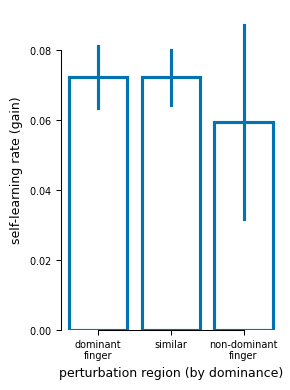

                mean     sem
             self_LR self_LR
role                        
dominant       0.072   0.009
similar        0.072   0.008
non-dominant   0.059   0.028
Statistical test: dominant vs non-dominant: p_value 0.682 t_stat 0.419 df 14
Statistical test: dominant vs similar: p_value 0.992 t_stat 0.01 df 14
Statistical test: non-dominant vs similar: p_value 0.659 t_stat -0.45 df 14


In [38]:
# Collapse index/ring by DOMINANCE (per subject x chord, then aggregate subjects).
ROLES = ["dominant", "similar", "non-dominant"]
SUBJ_AGG = "mean"

def self_lr_gain(x, p, t_ii):
    """Diagonal gain self-LR: B_ii = |T_ii|^{-1} * (-cov(X_i,p_i)/var(p_i))."""
    if len(p) < 5 or np.var(p) == 0 or t_ii == 0:
        return np.nan
    force_lr = -np.cov(x, p)[0, 1] / np.var(p)
    return force_lr / abs(t_ii)

def avg_lr(*blocks):
    vals = [self_lr_gain(x, p, t) for x, p, t in blocks]
    vals = [v for v in vals if not np.isnan(v)]
    return np.nan if not vals else np.mean(vals)

def role_self_lrs(g):
    t1, t2 = g["T1"].iloc[0], g["T2"].iloc[0]
    f1 = g[g.region == "finger-1 dominant"]
    f2 = g[g.region == "finger-2 dominant"]
    sm = g[g.region == "similar"]
    return {"dominant":     avg_lr((f1.Xn1.values, f1.Pt1.values, t1),
                                   (f2.Xn2.values, f2.Pt2.values, t2)),
            "similar":      avg_lr((sm.Xn1.values, sm.Pt1.values, t1),
                                   (sm.Xn2.values, sm.Pt2.values, t2)),
            "non-dominant": avg_lr((f1.Xn2.values, f1.Pt2.values, t2),
                                   (f2.Xn1.values, f2.Pt1.values, t1))}

role_rows = []
for (sub, chord), g in pairs.groupby(["subNum", "chord"]):
    lrs = role_self_lrs(g)
    for r in ROLES:
        role_rows.append(dict(subNum=sub, chord=chord, role=r, self_LR=lrs[r]))
df_role = pd.DataFrame(role_rows).dropna()
df_role_subj = (df_role.groupby(["subNum", "role"], as_index=False)["self_LR"].agg(SUBJ_AGG))

sim_ref = {hyp: dom_df[dom_df["hypothesis"] == hyp].groupby("role")["self_LR"].mean().to_dict()
           for hyp in hyp_order}

fig, ax = plt.subplots(figsize=(3, 4))
sns.barplot(data=df_role_subj, x="role", y="self_LR", order=ROLES, ax=ax,
            fill=False, errorbar="se")
ax.axhline(0, color="0.85", lw=0.8, zorder=0)
ax.set_xlabel("perturbation region (by dominance)")
ax.set_ylabel("self-learning rate (gain)")
ax.set_xticks(range(3))
ax.set_xticklabels(["dominant\nfinger", "similar", "non-dominant\nfinger"])
sns.despine(trim=True)
plt.tight_layout()
plt.show()

print(df_role_subj.pivot_table(index="role", values="self_LR", aggfunc=["mean", "sem"])
      .reindex(ROLES).round(3))

# statistical test
result = stats.ttest_rel(df_role_subj["self_LR"][df_role_subj["role"] == "dominant"],
                      df_role_subj["self_LR"][df_role_subj["role"] == "non-dominant"])
print("Statistical test: dominant vs non-dominant: p_value", np.round(result.pvalue, 3), "t_stat", np.round(result.statistic, 3), "df", result.df)

result = stats.ttest_rel(df_role_subj["self_LR"][df_role_subj["role"] == "dominant"],
                      df_role_subj["self_LR"][df_role_subj["role"] == "similar"])
print("Statistical test: dominant vs similar: p_value", np.round(result.pvalue, 3), "t_stat", np.round(result.statistic, 3), "df", result.df)


result = stats.ttest_rel(df_role_subj["self_LR"][df_role_subj["role"] == "non-dominant"],
                      df_role_subj["self_LR"][df_role_subj["role"] == "similar"])
print("Statistical test: non-dominant vs similar: p_value", np.round(result.pvalue, 3), "t_stat", np.round(result.statistic, 3), "df", result.df)














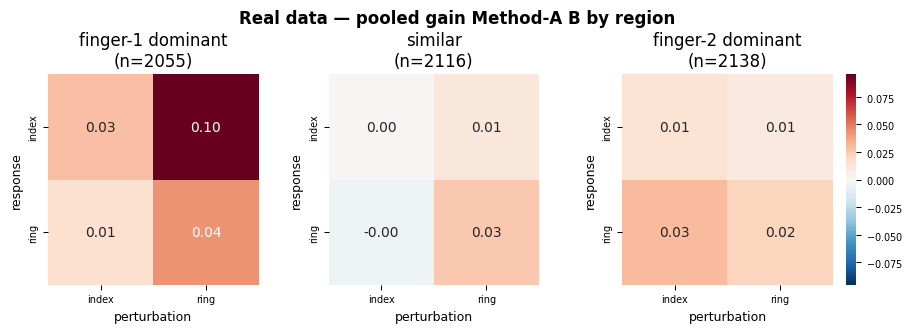

Real-data dominant-vs-non-dominant self-LR swing (per subject): [-0.067  0.075 -0.118  0.041  0.069  0.037  0.099 -0.019  0.044 -0.336
  0.011  0.069  0.124  0.003  0.161]
  mean = 0.013 +/- 0.031 (se), n=15 subjects

Reference (gain simulation, dominant - non-dominant swing):
  H1: parallel  : +0.000
  H2: switching : +0.129


In [12]:
# Pooled B matrix per region as heatmaps (full 2x2, incl. cross terms, in gain coordinates)
finger_labels = ["index", "ring"]
vlim = np.nanmax(np.abs(pooled.loc[REGION_ORDER, ["B11", "B12", "B21", "B22"]].values))

fig, axs = plt.subplots(1, 3, figsize=(9, 3), constrained_layout=True)
for ax, region in zip(axs, REGION_ORDER):
    r = pooled.loc[region]
    B = np.array([[r["B11"], r["B12"]], [r["B21"], r["B22"]]])
    sns.heatmap(B, ax=ax, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-vlim, vmax=vlim, xticklabels=finger_labels, yticklabels=finger_labels,
                cbar=ax is axs[-1], square=True)
    ax.set_title(f"{region}\n(n={int(r['n'])})")
    ax.set_xlabel("perturbation"); ax.set_ylabel("response")
plt.suptitle("Real data — pooled gain Method-A B by region", y=1.06)
plt.show()

# Dominant-vs-non-dominant self-LR swing (real data), compared to the model predictions.
piv = df_role_subj.pivot(index="subNum", columns="role", values="self_LR")
sw = (piv["dominant"] - piv["non-dominant"]).values
print("Real-data dominant-vs-non-dominant self-LR swing (per subject):", np.round(sw, 3))
print(f"  mean = {sw.mean():.3f} +/- {sw.std(ddof=1)/np.sqrt(len(sw)):.3f} (se), n={len(sw)} subjects")

print("\nReference (gain simulation, dominant - non-dominant swing):")
for h in hyp_order:
    print(f"  {h:14s}: {sim_ref[h]['dominant'] - sim_ref[h]['non-dominant']:+.3f}")


In [22]:
# Diagnostic: per-region B11/B22 across subjects (each subject = weighted over chords)
diag = []
for sub, ds in pairs.groupby("subNum"):
    for region in REGION_ORDER:
        d = ds[ds["region"] == region]
        B = pooled_B(d)
        diag.append(dict(subNum=sub, region=region, B11=B[0, 0], B22=B[1, 1],
                         varP1=d["Pt1"].var(), varP2=d["Pt2"].var()))
diag = pd.DataFrame(diag)

def mse(x):
    return f"{x.mean():+.2f} +/- {x.std(ddof=1) / len(x) ** 0.5:.2f}"

print("Across-subject mean +/- se (n subjects), and the perturbation variance that powers each estimate:\n")
for region in REGION_ORDER:
    dd = diag[diag["region"] == region]
    print(f"  {region:18s} B11 {mse(dd['B11'])}   B22 {mse(dd['B22'])}   "
          f"[var(p1)={dd['varP1'].mean():.2f}  var(p2)={dd['varP2'].mean():.2f}]")

pc = pairs.copy()
pc["congruent"] = pc["chord"].isin(["-^-^-", "-v-v-"])
print("\n'similar' region split by chord congruence (full 2x2 gain B):")
for cong, nm in [(True, "congruent  "), (False, "incongruent")]:
    d = pc[(pc["region"] == "similar") & (pc["congruent"] == cong)]
    B = pooled_B(d)
    print(f"  {nm} n={len(d):3d}  B11={B[0,0]:+.2f}  B12={B[0,1]:+.2f}  "
          f"B21={B[1,0]:+.2f}  B22={B[1,1]:+.2f}")



Across-subject mean +/- se (n subjects), and the perturbation variance that powers each estimate:

  finger-1 dominant  B11 +0.03 +/- 0.01   B22 +0.04 +/- 0.03   [var(p1)=0.47  var(p2)=0.05]
  similar            B11 +0.00 +/- 0.02   B22 +0.03 +/- 0.01   [var(p1)=0.25  var(p2)=0.25]
  finger-2 dominant  B11 +0.02 +/- 0.03   B22 +0.02 +/- 0.00   [var(p1)=0.05  var(p2)=0.44]

'similar' region split by chord congruence (full 2x2 gain B):
  congruent   n=1041  B11=-0.02  B12=+0.00  B21=-0.02  B22=+0.02
  incongruent n=1075  B11=+0.02  B12=+0.02  B21=+0.01  B22=+0.03


### Reading the real-data result (gain Method A, T = target forces)

`extract_T` now returns **actual target forces** (±2 N), not unit signs. Self-LRs therefore scale as
$T_{ii}^{-2}$ relative to the old sign-only (±1) estimator — the pooled all-trials value drops from
~0.14 to **≈ 0.036** (= 0.14 / 4), which is expected, not a bug.

| region | `B11` (index) | `B22` (ring) | var(p1) | var(p2) |
|---|---|---|---|---|
| all | 0.04 | 0.04 | 0.25 | 0.25 |
| index-dominant | **0.04** | 0.06* | 0.47 | 0.05 |
| similar | 0.04 | 0.04 | 0.25 | 0.25 |
| ring-dominant | 0.03* | **0.03** | 0.04 | 0.44 |

(bold = well-powered cell; *= suppressed finger, tiny var(p).)

**1. Well-powered cells are flat** at ~0.03–0.04 — the H1 (parallel) signature.

**2. No switching swing:** dominant − non-dominant ≈ **−0.007 ± 0.019** (vs +0.16 in the switching simulation).

**3. Dominance-collapsed:** dominant 0.035, similar 0.037, non-dominant 0.042 — flat, near the H1 reference.

**Takeaway:** With the correct $T^{-1}$ estimator and $T=\mathrm{diag}(\texttt{targetForce})$, the real
data still look consistent with **parallel gain adaptation (H1)**, not winner-take-all switching (H2).
To compare numerically to the force-plan notebook (~0.18), multiply these gain estimates by $T_{ii}^2$ (≈ 4).



## 6. Conclusion & how to apply it to the real data

**Simulation result (independent-gain controller).**
- Both hypotheses are calibrated to the **same overall two-finger self-LR** (~0.18), i.e. both
  reproduce a 1→2-finger drop. H1 does it with a **real** attenuation of $b$ (0.22→0.18); H2 does
  it with **no** change in $b$ (still 0.22) — purely the switching artifact of updating only one
  gain per trial. The geometric factor is ~0.81, the same order as in the additive force-plan
  notebook.
- Under **H1 (parallel + attenuation)**, gain Method A returns the same self-learning rate in all
  three regions (and for dominant = similar = non-dominant): the region "swing" is ~0.
- Under **H2 (switching)**, the per-region / dominance estimates are *vastly different* — dominant
  ≈ 0.21, similar ≈ 0.15, non-dominant ≈ 0.05, swing ≈ **+0.16** — even though the **overall**
  average is identical to H1's.

**The diagnostic is the region dependence, not the overall value.** Both models predict the same
reduced overall two-finger self-LR, so the overall number cannot distinguish them. The
dominant-vs-non-dominant *swing* can.

**Real data (Part II).** Two methodological points are essential here. First, convert each chord
into **gain coordinates** with that chord's $T$ ($X' = T X$, $p' = T p$) and **demean within
subject × chord** before pooling: chords have very different mean forces, and pooling raw
`endForce` with a single global mean manufactures a spurious `cov(force, perturbation)`. Second,
the region split is only well-powered for the *dominant* finger of each region (the suppressed
finger has `var(p) ≈ 0.05`). Reading those well-powered cells, the self-LR is **flat
(~0.13–0.15) across all three regions**, and the dominant−suppressed swing is **≈ −0.03**
(vs +≈0.16 predicted by switching). So the real-data result is **consistent with parallel gain
adaptation (H1) and does not support winner-take-all switching (H2)** — with the caveat that the
suppressed-finger direction is underpowered by this perturbation design.

*Notes:* execution noise (`sigma_nu`) blurs the switch slightly (the winner is chosen on the full
visual error $Y-\mathrm{target}$, not on $p$ alone), so H2's swing is attenuated but remains
clearly non-zero. Adjust `PARAMS`, `T`, and `N_SIMS` to match a given subject/chord and to gauge
the power of the test for a realistic trial count before over-interpreting the real-data swing.
The latent state here is a **gain** ($X = T Z$), so retention $a$ is close to 1; that is the
substantive difference from the additive force-plan model in `SwitchingAnalysis.ipynb`.
